# 02 Cleaning check (Corridor B)
Runs the Phase 2 pipeline from `src/data/clean.py` on the untouched raw files and checks the result. Outputs are in `data/processed/`; the full rule list is in `reports/phase2_cleaning_log.md`.

In [1]:
import sys, os
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, ".")
import pandas as pd, matplotlib.pyplot as plt
from src.data.clean import build_tables
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 300)
tables, log, extras = build_tables()
stations, trains, stops = tables["stations"], tables["trains"], tables["stops"]
print({k: len(v) for k, v in tables.items()})

{'stations': 110, 'trains': 229, 'stops': 15873}


## Counts before and after each step

In [2]:
rows = [{"step": e["step"], "rule": e["message"][:90], **{k: v for k, v in e["counts"].items()}} for e in log.entries]
for r in rows:
    print(f"{r['step']:15s} {r['rule']}")
    print("                ", {k: v for k, v in r.items() if k not in ("step", "rule")})

raw             raw schedules.json
                 {'rows': 417080, 'trains': 5208, 'stations': 8539}
dedup           exact duplicate stop rows dropped (all columns equal except id)
                 {'dropped': 443, 'rows_after': 416637}
corridor        corridor trains = stop at 2+ of ['NDLS', 'TDL', 'ETW', 'CNB', 'ALD', 'MGS']
                 {'corridor_trains': 229, 'stop_at_4plus_anchors': 161, 'wide_stations': 430, 'stations_with_20plus_trains': 122, 'removed_offline': 12, 'core_stations': 110}
full_routes     full routes of corridor trains
                 {'trains': 229, 'stops': 49207}
none_legit      origin has no arrival / terminus has no departure (legitimate, kept as null)
                 {'origin_no_arrival': 225, 'terminus_no_departure': 223}
none_both       stop with neither arrival nor departure: dropped (no time to use)
                 {'dropped': 3215, 'of_which_core': 40, 'of_which_origin_or_terminus': 5}
none_fill       one time missing away from origin/terminus:

In [3]:
# the same numbers as a before -> after table
g = {e["step"]: e["counts"] for e in log.entries}
print(f"schedule rows         {g['raw']['rows']:>7} -> {g['dedup']['rows_after']:>7}   (dedup drops {g['dedup']['dropped']})")
print(f"trains                {g['raw']['trains']:>7} -> {g['corridor']['corridor_trains']:>7}   (2+ anchors)")
print(f"corridor-train stops  {g['full_routes']['stops']:>7} -> {g['core_filter']['stops_before']:>7}   (time rules drop {g['full_routes']['stops'] - g['core_filter']['stops_before']})")
print(f"  of which at core    {'':>7}    {g['core_filter']['stops_after']:>7}")
print(f"stations              {g['raw']['stations']:>7} -> {g['corridor']['wide_stations']:>7} wide -> {g['corridor']['core_stations']} core")
print(f"trains after short-train filter: {len(trains)}  (dropped {g['short_trains']['dropped']})")

schedule rows          417080 ->  416637   (dedup drops 443)
trains                   5208 ->     229   (2+ anchors)
corridor-train stops    49207 ->   45957   (time rules drop 3250)
  of which at core                 15873
stations                 8539 ->     430 wide -> 110 core
trains after short-train filter: 229  (dropped 0)


## Three full routes (core stops, with times)
A Rajdhani, a Passenger, and the shortest main-line train (20+ core stops) whose journey crosses midnight inside the corridor. `halt_min` 0 = pass-through, `is_halt` marks real halts and origin/terminus.

In [4]:
cols = ["sequence", "station", "scheduled_arrival", "scheduled_departure", "day_offset", "halt_min", "is_halt", "minutes_from_start"]
span = stops.groupby("train").day_offset.nunique()
n_core = stops.groupby("train").size()
ok = trains.set_index("number").query("~leaves_main_line and n_core_stops >= 20").index
cand = n_core[[t for t in span[span > 1].index if t in ok]]
mid = cand.sort_values().index[0]
for tn in ["12302", "51809", mid]:
    t = trains.set_index("number").loc[tn]
    print(f"\n=== {tn} {t['name']} | {t['type']} | {t.source} -> {t.destination} | core stops {t.n_core_stops} of {t.n_full_route_stops} | entered_mid_route={t.entered_mid_route}")
    print(stops[stops.train == tn][cols].to_string(index=False))


=== 12302 New Delhi-Howrah Rajdhani Express | Rajdhani | NDLS -> HWH | core stops 110 of 218 | entered_mid_route=False
 sequence station scheduled_arrival scheduled_departure  day_offset  halt_min  is_halt  minutes_from_start
        0    NDLS               NaN            17:00:00           0       0.0     True                 0.0
        1     CSB          17:01:00            17:01:00           0       0.0    False                 1.0
        2     TKJ          17:02:00            17:02:00           0       0.0    False                 2.0
        3    ANVR          17:08:00            17:08:00           0       0.0    False                 8.0
        4    ANVT          17:08:00            17:08:00           0       0.0    False                 8.0
        5     CNJ          17:09:00            17:09:00           0       0.0    False                 9.0
        6     SBB          17:11:00            17:11:00           0       0.0    False                11.0
        7     GZB       

## Halt minutes

core stop rows: 15873; real halts (is_halt): 1380; halts with minutes > 0: 1248; max 50 min


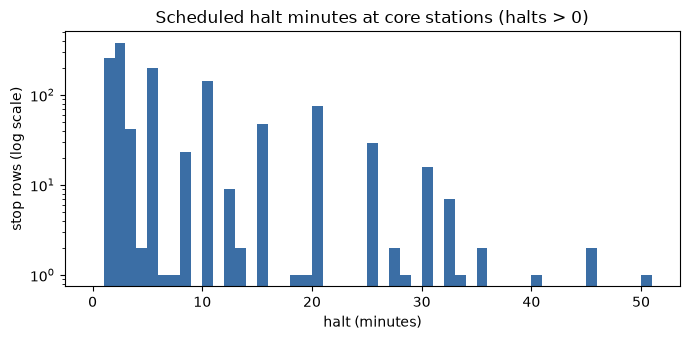

In [5]:
halts = stops[stops.is_halt & (stops.halt_min > 0)].halt_min
print(f"core stop rows: {len(stops)}; real halts (is_halt): {int(stops.is_halt.sum())}; halts with minutes > 0: {len(halts)}; max {halts.max():.0f} min")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(halts, bins=range(0, int(halts.max()) + 2), color="#3b6ea5")
ax.set_yscale("log"); ax.set_xlabel("halt (minutes)"); ax.set_ylabel("stop rows (log scale)")
ax.set_title("Scheduled halt minutes at core stations (halts > 0)")
plt.tight_layout(); plt.show()

## Validation

In [6]:
from src.data.validate import validate
fails = validate(stations, trains, stops)
print("validation failures:", fails if fails else "none")

validation failures: none
